# Cost of Living Visualiser — Data Exploration

First look at the price dataset: clean it, build one row per country, and compare salaries with fixed monthly costs (rent, bills and transport).

run in terminal and restart kernel
```pip install numpy pandas matplotlib plotly nbformat```

In [35]:
# Imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from IPython.display import display

%matplotlib inline
pio.renderers.default = 'iframe_connected'  # show Plotly charts in any Jupyter version

colour_blue = '#0072B2'
colour_green = '#009E73'
colour_orange = '#D55E00'

## Load and inspect the raw CSV

In [36]:
df = pd.read_csv('../data/europe_allyouneed.csv', encoding='utf-8-sig')  # utf-8-sig removes the hidden character before 'item'

print('Shape:', df.shape)
print('Countries:', df['country'].nunique(), '| Items:', df['item'].nunique())
display(df.head())

Shape: (1998, 5)
Countries: 37 | Items: 53


,item,category,price,price_range,country
0,Meal at an Inexpensive Restaurant,eat out,€25.70,€16.15-€44.05,Iceland
1,Meal for Two at a Mid-Range Restaurant (Three ...,eat out,€110.13,€73.42-€220.26,Iceland
2,Combo Meal at McDonald's (or Equivalent Fast-F...,eat out,€21.62,€18.36-€25.70,Iceland
3,Domestic Draft Beer (0.5 Liter),eat out,€11.01,€7.34-€12.85,Iceland
4,Imported Beer (0.33 Liter Bottle),eat out,€11.01,€7.34-€13.22,Iceland


In [37]:
df.info()
display(df.isna().sum().sort_values(ascending=False).to_frame('missing'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1998 entries, 0 to 1997
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   item         1998 non-null   object
 1   category     1998 non-null   object
 2   price        1985 non-null   object
 3   price_range  1924 non-null   object
 4   country      1998 non-null   object
dtypes: object(5)
memory usage: 78.2+ KB


,missing
price_range,74
price,13
item,0
category,0
country,0


**Current Dataset State**

- One row = one item price in one country (long format)
- `price` was read as text because values contain "€" and thousands separators (e.g. `€61,600.59`)
- `price` is missing only for **Minimum Wage** in some countries (countries without a statutory minimum wage)
- `price_range` is missing more often — we only use it as supporting information
- `price_range` contains outliers so the feature itself may not be as useful

## Clean the prices

Remove "€" and `,`, then convert to numbers.

In [38]:
df['price'] = pd.to_numeric(df['price'].str.replace('€', '', regex=False)
                                       .str.replace(',', '', regex=False), errors='coerce')

print('Duplicate rows:', df.duplicated().sum())
display(df.loc[df['price'] == 0, ['item', 'country', 'price']])

Duplicate rows: 0


,item,country,price
664,Monthly Public Transport Pass (Regular Price),Malta,0.0


**Finding:** Malta's monthly public transport pass is €0. This is plausible rather than an error — Malta made public transport free for residents in 2022 — so the value is kept.

## One row per country

Only items that are **already monthly prices** are used, so no quantities have to be guessed:

monthly cost = rent (1-bed, outside centre) + utilities + internet + mobile + transport pass

money left = net salary − monthly cost

In [39]:
items = {
    'Average Monthly Net Salary (After Tax)': 'net_salary',
    '1 Bedroom Apartment Outside of City Centre': 'rent',
    'Basic Utilities for 85 m2 Apartment (Electricity, Heating, Cooling, Water, Garbage)': 'utilities',
    'Broadband Internet (Unlimited Data, 60 Mbps or Higher)': 'internet',
    'Mobile Phone Plan (Monthly, with Calls and 10GB+ Data)': 'mobile',
    'Monthly Public Transport Pass (Regular Price)': 'transport',
}

countries = (df[df['item'].isin(items)]
             .pivot(index='country', columns='item', values='price')
             .rename(columns=items)
             .rename_axis(columns=None)
             .reset_index())
countries = countries[['country'] + list(items.values())]

countries['monthly_cost'] = countries[['rent', 'utilities', 'internet', 'mobile', 'transport']].sum(axis=1)
countries['money_left'] = countries['net_salary'] - countries['monthly_cost']
countries['rent_pct_of_salary'] = (countries['rent'] / countries['net_salary'] * 100).round(1)

display(countries.sort_values('money_left', ascending=False).round(0))

,country,net_salary,rent,utilities,internet,mobile,transport,monthly_cost,money_left,rent_pct_of_salary
34,Switzerland,6382.0,1438.0,249.0,51.0,34.0,89.0,1862.0,4520.0,22.0
7,Denmark,3678.0,807.0,194.0,36.0,15.0,80.0,1131.0,2547.0,22.0
24,Norway,3773.0,979.0,246.0,66.0,35.0,75.0,1402.0,2370.0,26.0
14,Iceland,4250.0,1757.0,91.0,80.0,29.0,85.0,2043.0,2207.0,41.0
11,Germany,2921.0,628.0,305.0,43.0,22.0,63.0,1062.0,1859.0,22.0
33,Sweden,2718.0,618.0,118.0,34.0,24.0,74.0,868.0,1850.0,23.0
22,Netherlands,3389.0,1162.0,231.0,45.0,20.0,90.0,1548.0,1841.0,34.0
9,Finland,2669.0,631.0,127.0,22.0,25.0,63.0,868.0,1800.0,24.0
2,Belgium,2717.0,768.0,207.0,48.0,20.0,55.0,1099.0,1619.0,28.0
1,Austria,2725.0,730.0,317.0,31.0,14.0,54.0,1145.0,1580.0,27.0


## Static chart — how much of a salary goes on rent?

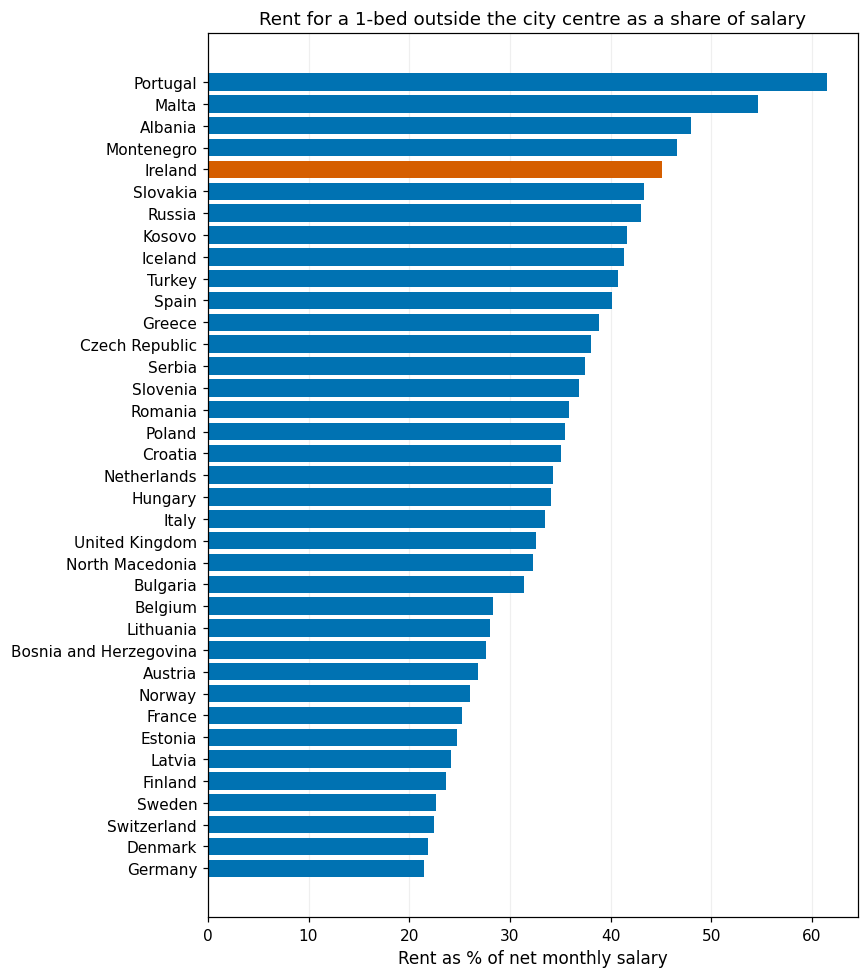

In [40]:
by_rent = countries.sort_values('rent_pct_of_salary')
colours = [colour_orange if c == 'Ireland' else colour_blue for c in by_rent['country']]

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(by_rent['country'], by_rent['rent_pct_of_salary'], color=colours)
ax.set_xlim(left=0)
ax.set_xlabel('Rent as % of net monthly salary')
ax.set_title('Rent for a 1-bed outside the city centre as a share of salary')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Interactive chart 1 — money left after fixed monthly costs

Hover over a bar to see the salary and cost behind it.

In [41]:
countries['status'] = np.where(countries['money_left'] >= 0, 'Money left', 'Short')

fig_left = px.bar(
    countries.sort_values('money_left'), x='money_left', y='country', orientation='h',
    color='status', color_discrete_map={'Money left': colour_green, 'Short': colour_orange},
    hover_data={'net_salary': ':,.0f', 'monthly_cost': ':,.0f', 'money_left': ':,.0f', 'status': False},
    labels={'money_left': 'Money left (€)', 'country': 'Country',
            'net_salary': 'Net salary (€)', 'monthly_cost': 'Monthly cost (€)'},
    title='Net salary minus rent, bills and transport', height=850,
)
fig_left.update_layout(template='plotly_white', showlegend=False)
fig_left.show()

## Interactive chart 2 — do higher salaries come with higher rent?

Each point is a country. Hover for details; drag to zoom, double-click to reset.

In [42]:
fig_scatter = px.scatter(
    countries, x='net_salary', y='rent', hover_name='country',
    hover_data={'net_salary': ':,.0f', 'rent': ':,.0f', 'rent_pct_of_salary': ':.1f'},
    labels={'net_salary': 'Net monthly salary (€)', 'rent': 'Rent, 1-bed outside centre (€)',
            'rent_pct_of_salary': 'Rent as % of salary'},
    title='Net salary vs rent by country',
)
fig_scatter.update_traces(marker={'size': 11, 'color': colour_blue})
fig_scatter.update_layout(template='plotly_white')
fig_scatter.show()

print('Correlation:', round(countries['net_salary'].corr(countries['rent']), 2))

Correlation: 0.86


## Notes

- Food and leisure are **not included yet** — the dataset only has unit prices for these, so we need to agree how to turn them into monthly amounts.
- Utilities are quoted for an 85 m² apartment, which is larger than a 1-bed.
- Average net salary is not everyone's income, and national averages hide differences between cities.
- A link between salary and rent is not proof that one causes the other.